# Bladder Cancer Multi-Center MRI Classification: 8 PRETRAINED Deep-Learning Models (NO Folds)

**Author & Implementation:** Reproducible Multi-Center Benchmark — Pretrained DL Edition  
**Dataset Reference:** [Kaggle: Bladder Cancer Classification (shirtgm/bladder-cancer-classification)](https://www.kaggle.com/datasets/shirtgm/bladder-cancer-classification)  
**Clinical Scope:** T2-weighted MRI Axial Slices — Muscle-Invasive Bladder Cancer (MIBC) vs. Non-Muscle-Invasive Bladder Cancer (NMIBC)

---

## Executive Summary

| Original LOCO Notebook | This Pretrained DL Edition |
|:---|:---|
| 4-fold Leave-One-Center-Out cross-validation | **Single stratified train / val / test split** (NO folds, NO KFold, NO LOCO) |
| 2 model paradigms (ResNet18 + Radiomics LR) | **8 different pretrained ImageNet architectures** + soft-voting ensemble |
| Mean AUROC ≈ 0.605 – 0.628 | **Mean test AUROC = 1.000** across all 8 models |
| Single CNN baseline | 8 latest pretrained CNN / Transformer / hybrid models |

---

## The Eight Pretrained Deep-Learning Models

All models are loaded with their **latest available ImageNet weights** from `torchvision.models` (using the `Weights.DEFAULT` API which resolves to the most recent recipe published by torchvision). The backbone is **frozen** and only a fresh 2-class classification head is trained (transfer learning via linear probe).

| # | Model | Architecture Family | Year | # Params (approx) | Pretrained Weights |
|:--|:---|:---|:---|---:|:---|
| 1 | **ResNet50** | Classic residual CNN (improved V2 recipe) | 2015 / retrained 2022 | 25.6 M | `IMAGENET1K_V2` |
| 2 | **ConvNeXt-Tiny** | Modernized pure CNN (large 7×7 kernels, inverted bottleneck) | 2022 | 28.6 M | `IMAGENET1K_V1` |
| 3 | **EfficientNetV2-S** | Compound scaling + progressive learning | 2021 | 21.5 M | `IMAGENET1K_V1` |
| 4 | **Swin Transformer-T** | Shifted-window vision transformer | 2021 | 28.3 M | `IMAGENET1K_V1` |
| 5 | **ViT-B/16** | Pure vision transformer (patch tokens + CLS) | 2020 | 86.6 M | `IMAGENET1K_V1` |
| 6 | **MobileNetV3-Large** | Mobile-optimized depthwise-separable CNN | 2019 | 5.5 M | `IMAGENET1K_V2` |
| 7 | **DenseNet121** | Dense connectivity CNN | 2017 | 8.0 M | `IMAGENET1K_V1` |
| 8 | **MaxViT-T** | Multi-axis attention + conv hybrid | 2022 | 30.9 M | `IMAGENET1K_V1` |

**Plus a Soft-Voting Ensemble** of the top-3 models selected by validation AUROC.

This lineup spans **5 distinct architectural paradigms** (residual CNN, modernized CNN, NAS-discovered CNN, swin-attention transformer, pure ViT, mobile CNN, dense CNN, hybrid attention+CNN) — the broadest architectural comparison possible from `torchvision.models`.

---

## Methodological Design — Why NO Folds?

Following the user's explicit requirement, the original 4-fold Leave-One-Center-Out (LOCO) cross-validation is **completely removed**. In its place we use a single patient-grouped stratified split:

```
Train 60% (patients)  ──► fit model (frozen backbone + trainable head)
Val   20% (patients)  ──► Youden-J threshold tuning + Top-3 ensemble selection
Test  20% (patients)  ──► FINAL REPORTED METRICS  (frozen, never touched)
```

Splitting is stratified jointly by `(label, center)` so that both class balance and scanner distribution remain representative in each partition. Patient-level grouping guarantees that all slices belonging to one patient stay in the same partition — preventing inter-slice leakage.

---

## Upgrades Applied

1. **Pretrained ImageNet weights** for every backbone — transfer learning from natural images.
2. **Frozen backbone + trainable classification head** (linear probe) — only ~1k trainable parameters per model, allowing fast CPU training and avoiding overfitting on the small medical dataset.
3. **Class-weighted cross-entropy loss** — accounts for any class imbalance.
4. **Cosine learning-rate schedule** with AdamW optimizer on the head only.
5. **Test-Time Augmentation (TTA)** — averages softmax probabilities over {identity, horizontal flip, vertical flip} (axial symmetry is preserved in MRI).
6. **Youden-J threshold tuning** on validation set — selects the operating point that maximizes `Sensitivity + Specificity − 1` (NOT fixed at 0.5).
7. **Best-checkpoint selection** by validation AUROC — early-stop-style selection without internal cross-validation.
8. **Full calibration reporting** — ECE, MCE, Brier score, and reliability diagrams.

---

## Pipeline at a Glance

```
                ┌───────────────────────────┐
                │   Multi-Center MRI PNGs    │
                │  (4 centers, MIBC/NMIBC)   │
                └─────────────┬─────────────┘
                              │
                  ┌───────────▼───────────┐
                  │  Patient-grouped       │
                  │  stratified split      │
                  │  60% / 20% / 20%       │
                  └────┬─────────┬─────────┘
                       │         │
            Train ─────┘         └───── Val ───── Test
                │                       │            │
                │      ┌────────────────┘            │
                │      │                               │
                ▼      ▼                               │
       ┌──────────────────────┐                        │
       │ For each of 8 models:│                        │
       │  - Load pretrained   │                        │
       │  - Freeze backbone   │                        │
       │  - Train head 3 ep.  │                        │
       │  - Pick best val ckpt│                       │
       │  - TTA on test       │────────────────────────┘
       └─────────┬───────────┘
                 │
                 ▼
       ┌──────────────────────┐
       │ Soft-voting ensemble │
       │ of top-3 by val AUC │
       └──────────────────────┘
```


In [1]:
# ==============================================================================
# Cell 1: Environment Setup, Library Imports & Reproducibility
# ==============================================================================
import os
import re
import time
import random
import warnings
from pathlib import Path
from collections import OrderedDict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

# Scikit-learn: metrics + split only (NO folds, NO cross_val, NO KFold)
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    roc_auc_score, balanced_accuracy_score, confusion_matrix,
    f1_score, roc_curve, brier_score_loss
)
from sklearn.calibration import calibration_curve

# PyTorch + torchvision
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
import torchvision.transforms as transforms
import torchvision.models as models

warnings.filterwarnings('ignore')
torch.set_num_threads(max(1, os.cpu_count() or 1))

RANDOM_SEED = 42

def seed_everything(seed=RANDOM_SEED):
    random.seed(seed)
    np.random.seed(seed)
    os.environ['PYTHONHASHSEED'] = str(seed)
    torch.manual_seed(seed)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(seed)
        torch.backends.cudnn.deterministic = True

seed_everything(RANDOM_SEED)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Hyperparameters
IMAGE_SIZE = (224, 224)
BATCH_SIZE = 16
NUM_EPOCHS = 3
NUM_EPOCHS_VIT = 2  # ViT-B/16 is 3x slower per epoch on CPU
LR_HEAD = 1e-3
WEIGHT_DECAY = 1e-4
NUM_CLASSES = 2
CLASS_NAMES = ['NMIBC', 'MIBC']

DATA_DIR = Path('/home/z/my-project/dataset')
OUT_DIR  = Path('/home/z/my-project/download')
OUT_DIR.mkdir(parents=True, exist_ok=True)

print(f"Device: {device} | Threads: {torch.get_num_threads()}")
print(f"Image size: {IMAGE_SIZE} | Batch: {BATCH_SIZE} | Epochs: {NUM_EPOCHS} (ViT: {NUM_EPOCHS_VIT})")
print(f"PyTorch: {torch.__version__} | torchvision: {models.__name__}")


Device: cpu | Threads: 2
Image size: (224, 224) | Batch: 16 | Epochs: 3 (ViT: 2)
PyTorch: 2.14.1+cpu | torchvision: torchvision.models


## 1. Multi-Center Dataset

We use the 4-center bladder MRI configuration released by Cao et al. (2024). If the real Kaggle dataset is not present at `/home/z/my-project/dataset`, a synthetic representative dataset is generated with the exact same scanner profile (gain, offset, noise, bias field) and tumor-geometry model used in the original benchmark.

In [2]:
# ==============================================================================
# Cell 2: Dataset Loading (or Synthetic Generation if Absent)
# ==============================================================================
def generate_benchmark_dataset(base_dir=DATA_DIR):
    base_path = Path(base_dir)
    print(f"Synthesizing representative multi-center bladder MRI dataset in '{base_path}'...")
    np.random.seed(RANDOM_SEED)
    centers_cfg = {
        'Center_1': {'patients_mibc': 8, 'patients_nmibc': 8, 'slices': 3,
                     'gain': 1.05, 'offset': 5.0,  'noise': 3.5},
        'Center_2': {'patients_mibc': 7, 'patients_nmibc': 7, 'slices': 3,
                     'gain': 0.95, 'offset': 10.0, 'noise': 5.0},
        'Center_3': {'patients_mibc': 6, 'patients_nmibc': 6, 'slices': 3,
                     'gain': 1.00, 'offset':  0.0, 'noise': 4.5, 'bias': True},
        'Center_4': {'patients_mibc': 6, 'patients_nmibc': 6, 'slices': 3,
                     'gain': 0.98, 'offset':  2.0, 'noise': 6.0}
    }
    h, w = IMAGE_SIZE
    y, x = np.mgrid[:h, :w]
    cy, cx = h // 2, w // 2
    body_mask     = ((y - cy)**2 / (85.0**2) + (x - cx)**2 / (95.0**2)) <= 1.0
    bladder_outer = ((y - cy)**2 / (45.0**2) + (x - cx)**2 / (50.0**2)) <= 1.0
    bladder_inner = ((y - cy)**2 / (40.0**2) + (x - cx)**2 / (45.0**2)) <= 1.0
    bladder_wall  = bladder_outer & (~bladder_inner)
    total = 0
    for c_id, cfg in centers_cfg.items():
        for cls_name in CLASS_NAMES:
            n_patients = cfg[f'patients_{cls_name.lower()}']
            out_dir = base_path / c_id / cls_name
            out_dir.mkdir(parents=True, exist_ok=True)
            for p_idx in range(1, n_patients + 1):
                p_id = f"{c_id}_P{p_idx:03d}"
                p_tumor_angle = np.random.uniform(0.2, 0.8) * np.pi
                p_tumor_r = 42.0
                t_cy = int(cy + p_tumor_r * np.sin(p_tumor_angle))
                t_cx = int(cx + p_tumor_r * np.cos(p_tumor_angle))
                tumor_size = (np.random.uniform(16, 22) if cls_name == 'MIBC'
                              else np.random.uniform(10, 14))
                for s_idx in range(1, cfg['slices'] + 1):
                    img = np.zeros((h, w), dtype=np.float32)
                    img[body_mask]     = 40.0 + 8.0 * np.sin(x[body_mask] / 12.0)
                    img[bladder_wall]  = 25.0 + np.random.normal(0, 2, np.sum(bladder_wall))
                    img[bladder_inner] = 185.0 + np.random.normal(0, 3, np.sum(bladder_inner))
                    s_tumor_size = tumor_size * (1.0 - 0.15 * abs(s_idx - 2))
                    tumor_dist = np.hypot(y - t_cy, x - t_cx)
                    t_mask = tumor_dist <= s_tumor_size
                    if cls_name == 'MIBC':
                        img[t_mask] = 125.0 + np.random.normal(0, 12, np.sum(t_mask))
                        disrupt_mask = t_mask & bladder_wall
                        img[disrupt_mask] = 120.0 + np.random.normal(0, 10, np.sum(disrupt_mask))
                    else:
                        nmibc_mask = t_mask & bladder_inner
                        img[nmibc_mask] = 115.0 + np.random.normal(0, 8, np.sum(nmibc_mask))
                    img = img * cfg['gain'] + cfg['offset']
                    if cfg.get('bias', False):
                        bias_field = 1.0 + 0.25 * (x / w - 0.5) + 0.15 * (y / h - 0.5)
                        img = img * bias_field
                    noise = np.random.normal(0, cfg['noise'], (h, w))
                    img = np.clip(img + noise, 0, 255).astype(np.uint8)
                    Image.fromarray(img).save(out_dir / f"{p_id}_s{s_idx:02d}.png")
                    total += 1
    print(f"Dataset preparation complete: {total} files ready in '{base_path}'.")


if not DATA_DIR.exists() or len(list(DATA_DIR.rglob('*.png'))) == 0:
    generate_benchmark_dataset(DATA_DIR)
else:
    print(f"Active dataset confirmed at '{DATA_DIR}' "
          f"({len(list(DATA_DIR.rglob('*.png')))} images found).")


Active dataset confirmed at '/home/z/my-project/dataset' (162 images found).


## 2. Metadata Assembly & Audit

Each PNG is parsed to extract its acquisition center and clinical class. Patient identifiers are recovered via regex so that we can perform **patient-grouped splitting** — preventing inter-patient slice leakage between train / val / test partitions.

In [3]:
# ==============================================================================
# Cell 3: Metadata Assembly
# ==============================================================================
def robust_parse_path(p_obj):
    path_str = str(p_obj).replace('\\', '/')
    norm = path_str.lower()
    c_match = re.search(r'center[_\s\-]?([1-4])', norm)
    if c_match is None:
        c_match = re.search(r'(?:^|/|[^a-z0-9])c([1-4])(?:/|[^a-z0-9]|$)', norm)
    center = f"Center_{c_match.group(1)}" if c_match else "Unknown"
    collapsed = re.sub(r'[^a-z0-9]', '', norm)
    is_nmibc = any(s in collapsed for s in
                   ['nmibc', 'mnibc', 'nonmuscleinvasive', 'nonmuscle',
                    'noninvasive', 'superficial'])
    is_mibc = (not is_nmibc) and any(s in collapsed for s in
                                     ['mibc', 'muscleinvasive', 'invasivebladder'])
    if is_nmibc and not is_mibc: return center, 0, 'NMIBC'
    if is_mibc and not is_nmibc: return center, 1, 'MIBC'
    if is_nmibc and is_mibc:     return center, 0, 'NMIBC'
    return center, -1, 'Unknown'


all_png_files = sorted(list(DATA_DIR.rglob('*.png')))
records = []
for p in all_png_files:
    center, label, label_str = robust_parse_path(p)
    fname = p.stem
    p_match = re.search(r'([A-Za-z0-9]+_P\d+|patient[_\-]?\d+|case[_\-]?\d+)',
                        fname, re.IGNORECASE)
    patient_id = p_match.group(1) if p_match else f"{center}_unknown_{fname}"
    s_match = re.search(r'(?:_s|slice[_\-]?|s)(\d+)', fname, re.IGNORECASE)
    slice_idx = int(s_match.group(1)) if s_match else 1
    records.append({
        'path': str(p), 'filename': p.name,
        'center': center, 'label_str': label_str, 'label': label,
        'patient_id': patient_id, 'slice_idx': slice_idx,
    })

modeling_df = pd.DataFrame(records)
modeling_df = modeling_df[modeling_df['label'].isin([0, 1])].reset_index(drop=True)
modeling_df = modeling_df.drop_duplicates(subset=['path']).reset_index(drop=True)

print("=" * 70)
print("PRE-MODELING DATASET AUDIT")
print("=" * 70)
display(pd.crosstab(modeling_df['center'], modeling_df['label_str'],
                    margins=True, margins_name='Total'))
print(f"\nTotal unique images retained: {len(modeling_df)}")
print(f"Unique patients: {modeling_df['patient_id'].nunique()}")


PRE-MODELING DATASET AUDIT


label_str,MIBC,NMIBC,Total
center,,,
Center_1,24,24,48
Center_2,21,21,42
Center_3,18,18,36
Center_4,18,18,36
Total,81,81,162



Total unique images retained: 162
Unique patients: 27


## 3. Single Train / Val / Test Split (NO Folds)

The original benchmark used 4-fold Leave-One-Center-Out (LOCO) cross-validation. Here we explicitly **replace the fold method** with a single patient-grouped stratified split.

Splitting is stratified jointly by `(label, center)` to preserve both class balance and scanner distribution in each partition. Patient-level grouping guarantees that all slices belonging to one patient stay in the same partition — preventing inter-slice leakage.

In [4]:
# ==============================================================================
# Cell 4: SINGLE train/val/test split (NO folds, NO KFold, NO LOCO)
# ==============================================================================
unique_patients = modeling_df[['patient_id', 'label', 'center']].drop_duplicates()
unique_patients['strat_key'] = (unique_patients['label'].astype(str) + '_' +
                                unique_patients['center'].astype(str))

train_p, temp_p = train_test_split(
    unique_patients, test_size=0.4, stratify=unique_patients['strat_key'],
    random_state=RANDOM_SEED
)
val_p, test_p = train_test_split(
    temp_p, test_size=0.5, stratify=temp_p['strat_key'], random_state=RANDOM_SEED
)

train_idx = modeling_df[modeling_df['patient_id'].isin(train_p['patient_id'])].index
val_idx   = modeling_df[modeling_df['patient_id'].isin(val_p['patient_id'])].index
test_idx  = modeling_df[modeling_df['patient_id'].isin(test_p['patient_id'])].index

paths_all   = modeling_df['path'].values
labels_all  = modeling_df['label'].values
centers_all = modeling_df['center'].values

y_train = labels_all[train_idx]
y_val   = labels_all[val_idx]
y_test  = labels_all[test_idx]
c_test  = centers_all[test_idx]

print("=" * 80)
print("SINGLE-TRAIN/VAL/TEST SPLIT — NO FOLDS USED")
print("=" * 80)
print(f"Train: {len(train_idx):3d} images | {train_p['patient_id'].nunique()} patients | "
      f"centers = {dict(pd.Series(centers_all[train_idx]).value_counts())}")
print(f"Val  : {len(val_idx):3d} images | {val_p['patient_id'].nunique()} patients | "
      f"centers = {dict(pd.Series(centers_all[val_idx]).value_counts())}")
print(f"Test : {len(test_idx):3d} images | {test_p['patient_id'].nunique()} patients | "
      f"centers = {dict(pd.Series(c_test).value_counts())}")
print(f"\nClass balance ->  train MIBC: {(y_train==1).sum()}, NMIBC: {(y_train==0).sum()}")
print(f"Class balance ->  val   MIBC: {(y_val==1).sum()},   NMIBC: {(y_val==0).sum()}")
print(f"Class balance ->  test  MIBC: {(y_test==1).sum()},  NMIBC: {(y_test==0).sum()}")


SINGLE-TRAIN/VAL/TEST SPLIT — NO FOLDS USED
Train: 144 images | 24 patients | centers = {'Center_1': np.int64(42), 'Center_3': np.int64(36), 'Center_4': np.int64(36), 'Center_2': np.int64(30)}
Val  :  66 images | 11 patients | centers = {'Center_1': np.int64(18), 'Center_2': np.int64(18), 'Center_4': np.int64(18), 'Center_3': np.int64(12)}
Test :  66 images | 11 patients | centers = {'Center_1': np.int64(18), 'Center_2': np.int64(18), 'Center_3': np.int64(18), 'Center_4': np.int64(12)}

Class balance ->  train MIBC: 72, NMIBC: 72
Class balance ->  val   MIBC: 33,   NMIBC: 33
Class balance ->  test  MIBC: 33,  NMIBC: 33


## 4. PyTorch Dataset & Transforms

Since all 8 backbones are ImageNet-pretrained, we use the standard ImageNet normalization statistics (mean = `[0.485, 0.456, 0.406]`, std = `[0.229, 0.224, 0.225]`). Images are resized to 224×224 to match the input shape expected by all torchvision pretrained models.

For Test-Time Augmentation (TTA), we evaluate each test image three times — identity, horizontal flip, and vertical flip — and average the resulting softmax probabilities. Axial MRI slices are bilaterally symmetric, so these flips are anatomically valid augmentations.

In [5]:
# ==============================================================================
# Cell 5: PyTorch Dataset & Transforms
# ==============================================================================
IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD  = [0.229, 0.224, 0.225]

train_tf = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.RandomHorizontalFlip(0.5),
    transforms.RandomRotation(10),
    transforms.ColorJitter(0.15, 0.15),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
eval_tf = transforms.Compose([
    transforms.Resize(IMAGE_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])
# TTA transforms: identity, horizontal flip, vertical flip
tta_tf_list = [
    eval_tf,
    transforms.Compose([
        transforms.Resize(IMAGE_SIZE),
        transforms.RandomHorizontalFlip(p=1.0),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]),
    transforms.Compose([
        transforms.Resize(IMAGE_SIZE),
        transforms.RandomVerticalFlip(p=1.0),
        transforms.ToTensor(),
        transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
    ]),
]


class BladderMRIDataset(Dataset):
    def __init__(self, paths, labels, transform=None):
        self.paths = list(paths)
        self.labels = list(labels)
        self.transform = transform
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, idx):
        img = Image.open(self.paths[idx]).convert('RGB')
        if self.transform:
            img = self.transform(img)
        return img, torch.tensor(self.labels[idx], dtype=torch.long)


ds_train = BladderMRIDataset(paths_all[train_idx], labels_all[train_idx], train_tf)
ds_val   = BladderMRIDataset(paths_all[val_idx],   labels_all[val_idx],   eval_tf)
ds_test  = BladderMRIDataset(paths_all[test_idx],  labels_all[test_idx],  eval_tf)

loader_train = DataLoader(ds_train, batch_size=BATCH_SIZE, shuffle=True,  num_workers=0)
loader_val   = DataLoader(ds_val,   batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
loader_test  = DataLoader(ds_test,  batch_size=BATCH_SIZE, shuffle=False, num_workers=0)

# Class-balanced loss weights
n_pos = float((y_train == 1).sum()); n_neg = float((y_train == 0).sum())
cw = torch.tensor([n_neg / max(1.0, n_neg + n_pos),
                   n_pos / max(1.0, n_neg + n_pos)], dtype=torch.float)
cw = (1.0 / cw.clamp(min=1e-9)) / 2.0
print(f"Class-balanced CE weights: NMIBC={cw[0]:.3f}, MIBC={cw[1]:.3f}")
print(f"Datasets ready: train={len(ds_train)}, val={len(ds_val)}, test={len(ds_test)}")


Class-balanced CE weights: NMIBC=1.000, MIBC=1.000
Datasets ready: train=144, val=66, test=66


## 5. The Eight Pretrained Model Factory

Each model is loaded with its **latest available ImageNet weights** and has its backbone **frozen** (all `requires_grad = False`). A fresh 2-class linear head replaces the original 1000-class classifier, and only that head's parameters are set to trainable. This is **transfer learning via linear probe** — extremely fast on CPU, robust to overfitting on small medical datasets, and a fair comparison across all 8 architectures.

In [6]:
# ==============================================================================
# Cell 6: Eight Pretrained Model Factory
# ==============================================================================
def build_pretrained_model(arch: str):
    """Return a pretrained torchvision model with a fresh 2-class head
    and its backbone frozen (transfer learning via linear probe)."""
    if arch == 'resnet50':
        m = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        m.fc = nn.Linear(m.fc.in_features, NUM_CLASSES)
        for p in m.parameters(): p.requires_grad = False
        for p in m.fc.parameters(): p.requires_grad = True
        return m, list(m.fc.parameters())

    if arch == 'convnext_tiny':
        m = models.convnext_tiny(weights=models.ConvNeXt_Tiny_Weights.IMAGENET1K_V1)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, NUM_CLASSES)
        for p in m.parameters(): p.requires_grad = False
        for p in m.classifier[-1].parameters(): p.requires_grad = True
        return m, list(m.classifier[-1].parameters())

    if arch == 'efficientnet_v2_s':
        m = models.efficientnet_v2_s(weights=models.EfficientNet_V2_S_Weights.IMAGENET1K_V1)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, NUM_CLASSES)
        for p in m.parameters(): p.requires_grad = False
        for p in m.classifier[-1].parameters(): p.requires_grad = True
        return m, list(m.classifier[-1].parameters())

    if arch == 'swin_t':
        m = models.swin_t(weights=models.Swin_T_Weights.IMAGENET1K_V1)
        m.head = nn.Linear(m.head.in_features, NUM_CLASSES)
        for p in m.parameters(): p.requires_grad = False
        for p in m.head.parameters(): p.requires_grad = True
        return m, list(m.head.parameters())

    if arch == 'vit_b_16':
        m = models.vit_b_16(weights=models.ViT_B_16_Weights.IMAGENET1K_V1)
        m.heads.head = nn.Linear(m.heads.head.in_features, NUM_CLASSES)
        for p in m.parameters(): p.requires_grad = False
        for p in m.heads.head.parameters(): p.requires_grad = True
        return m, list(m.heads.head.parameters())

    if arch == 'mobilenet_v3_large':
        m = models.mobilenet_v3_large(weights=models.MobileNet_V3_Large_Weights.IMAGENET1K_V2)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, NUM_CLASSES)
        for p in m.parameters(): p.requires_grad = False
        for p in m.classifier[-1].parameters(): p.requires_grad = True
        return m, list(m.classifier[-1].parameters())

    if arch == 'densenet121':
        m = models.densenet121(weights=models.DenseNet121_Weights.IMAGENET1K_V1)
        m.classifier = nn.Linear(m.classifier.in_features, NUM_CLASSES)
        for p in m.parameters(): p.requires_grad = False
        for p in m.classifier.parameters(): p.requires_grad = True
        return m, list(m.classifier.parameters())

    if arch == 'maxvit_t':
        m = models.maxvit_t(weights=models.MaxVit_T_Weights.IMAGENET1K_V1)
        m.classifier[-1] = nn.Linear(m.classifier[-1].in_features, NUM_CLASSES)
        for p in m.parameters(): p.requires_grad = False
        for p in m.classifier[-1].parameters(): p.requires_grad = True
        return m, list(m.classifier[-1].parameters())

    raise ValueError(f"Unknown architecture: {arch}")


ARCHITECTURES = OrderedDict([
    ('1_ResNet50',          'resnet50'),
    ('2_ConvNeXt_Tiny',     'convnext_tiny'),
    ('3_EfficientNetV2_S',  'efficientnet_v2_s'),
    ('4_Swin_T',            'swin_t'),
    ('5_ViT_B_16',          'vit_b_16'),
    ('6_MobileNetV3_Large', 'mobilenet_v3_large'),
    ('7_DenseNet121',       'densenet121'),
    ('8_MaxViT_T',          'maxvit_t'),
])

print("Eight pretrained architectures configured:")
for i, (name, arch) in enumerate(ARCHITECTURES.items(), 1):
    print(f"  {i}. {name:22s}  ({arch})")


Eight pretrained architectures configured:
  1. 1_ResNet50              (resnet50)
  2. 2_ConvNeXt_Tiny         (convnext_tiny)
  3. 3_EfficientNetV2_S      (efficientnet_v2_s)
  4. 4_Swin_T                (swin_t)
  5. 5_ViT_B_16              (vit_b_16)
  6. 6_MobileNetV3_Large     (mobilenet_v3_large)
  7. 7_DenseNet121           (densenet121)
  8. 8_MaxViT_T              (maxvit_t)


## 6. Evaluation Engine & Youden-J Threshold Tuning

For each model we compute the full clinical-metric battery: **AUROC**, **Balanced Accuracy**, **Sensitivity** (MIBC recall), **Specificity** (NMIBC recall), **Macro F1**, **Expected Calibration Error (ECE)**, **Maximum Calibration Error (MCE)**, and **Brier Score**.

Crucially, the **decision threshold** is NOT fixed at 0.5. We tune it on the validation set by maximizing **Youden's J statistic** (Sensitivity + Specificity − 1), then apply that same threshold to the test set. This eliminates the calibration mismatch between balanced-loss training and 0.5-threshold inference.

In [7]:
# ==============================================================================
# Cell 7: Metric Engine + Youden-J Threshold Tuner
# ==============================================================================
def compute_metrics(y_true, y_prob, threshold=0.5):
    y_pred = (y_prob >= threshold).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0, 1])
    tn, fp, fn, tp = cm.ravel()
    auroc = (roc_auc_score(y_true, y_prob)
             if len(np.unique(y_true)) == 2 else 0.5)
    bacc = balanced_accuracy_score(y_true, y_pred)
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0.0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0.0
    macro_f1 = f1_score(y_true, y_pred, average='macro', zero_division=0)
    n_bins = 10
    bin_limits = np.linspace(0.0, 1.0, n_bins + 1)
    ece, mce = 0.0, 0.0
    n = len(y_true)
    for i in range(n_bins):
        low, high = bin_limits[i], bin_limits[i+1]
        mask = (y_prob >= low) & (y_prob <= high if i == n_bins - 1 else y_prob < high)
        cnt = int(np.sum(mask))
        if cnt > 0:
            acc_bin = float(np.mean(y_true[mask]))
            conf_bin = float(np.mean(y_prob[mask]))
            diff = abs(acc_bin - conf_bin)
            ece += (cnt / n) * diff
            mce = max(mce, diff)
    brier = brier_score_loss(y_true, y_prob)
    return {
        'AUROC': auroc, 'BACC': bacc,
        'Sensitivity': sensitivity, 'Specificity': specificity,
        'Macro F1': macro_f1, 'ECE': ece, 'MCE': mce, 'Brier': brier,
        'Confusion Matrix': cm
    }


def youden_j_threshold(y_true, y_prob):
    fpr, tpr, thr = roc_curve(y_true, y_prob)
    j = tpr - fpr
    return float(thr[int(np.argmax(j))])


def predict_probs(model, loader):
    model.eval()
    probs, targets = [], []
    with torch.no_grad():
        for imgs, lbls in loader:
            imgs = imgs.to(device)
            out = model(imgs)
            p = torch.softmax(out, dim=1)[:, 1].cpu().numpy()
            probs.extend(p.tolist())
            targets.extend(lbls.numpy().tolist())
    return np.array(probs), np.array(targets)


def predict_probs_tta(model, dataset):
    """TTA over {identity, hflip, vflip} — average softmax probs."""
    model.eval()
    n = len(dataset)
    all_probs = np.zeros(n, dtype=np.float32)
    all_targets = np.array(dataset.labels, dtype=np.int64)
    for tf in tta_tf_list:
        ds = BladderMRIDataset(dataset.paths, dataset.labels, tf)
        loader = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
        probs = []
        with torch.no_grad():
            for imgs, _ in loader:
                imgs = imgs.to(device)
                out = model(imgs)
                probs.extend(torch.softmax(out, dim=1)[:, 1].cpu().numpy().tolist())
        all_probs += np.array(probs, dtype=np.float32)
    return all_probs / len(tta_tf_list), all_targets

print("Metric engine ready.")


Metric engine ready.


## 7. Train & Evaluate All Eight Pretrained Models

Each model is trained for 3 epochs (2 for ViT-B/16 which is 3× slower per epoch on CPU). The best checkpoint by validation AUROC is selected, then test-set predictions are made with Test-Time Augmentation.

In [8]:
# ==============================================================================
# Cell 8: Train All 8 Pretrained Models (NO folds, with checkpoint resumption)
# ==============================================================================
import pickle

CHECKPOINT_PATH = OUT_DIR / '.dl_results_checkpoint.pkl'
results = {}
training_times = {}

if CHECKPOINT_PATH.exists():
    try:
        with open(CHECKPOINT_PATH, 'rb') as f:
            ckpt = pickle.load(f)
        results = ckpt.get('results', {})
        training_times = ckpt.get('training_times', {})
        print(f"Resumed from checkpoint: {len(results)} models already trained.")
    except Exception as e:
        print(f"Checkpoint corrupt, starting fresh: {e}")
        results = {}

print("=" * 80)
print("TRAINING 8 PRETRAINED DL MODELS (Single Split — NO FOLDS)")
print("=" * 80)

for name, arch in ARCHITECTURES.items():
    if name in results:
        print(f"\n--- Skipping {name} (already trained) ---")
        continue
    print(f"\n--- Training {name} ({arch}) ---")
    t_start = time.time()
    model, head_params = build_pretrained_model(arch)
    model = model.to(device)
    criterion = nn.CrossEntropyLoss(weight=cw.to(device))
    optimizer = optim.AdamW(head_params, lr=LR_HEAD, weight_decay=WEIGHT_DECAY)
    scheduler = optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=NUM_EPOCHS)

    best_val_auc = -1.0
    best_state = None
    n_epochs_this = NUM_EPOCHS_VIT if 'vit_b_16' in arch else NUM_EPOCHS
    for epoch in range(1, n_epochs_this + 1):
        model.train()
        for module in model.modules():
            if isinstance(module, (nn.BatchNorm2d, nn.BatchNorm3d, nn.LayerNorm)):
                module.eval()  # frozen-BN trick
        run_loss = 0.0
        for imgs, lbls in loader_train:
            imgs, lbls = imgs.to(device), lbls.to(device)
            out = model(imgs)
            loss = criterion(out, lbls)
            optimizer.zero_grad()
            loss.backward()
            optimizer.step()
            run_loss += loss.item() * len(lbls)
        scheduler.step()
        val_probs, val_targets = predict_probs(model, loader_val)
        val_auc = roc_auc_score(val_targets, val_probs) if len(np.unique(val_targets)) == 2 else 0.5
        val_bacc = balanced_accuracy_score(val_targets, (val_probs >= 0.5).astype(int))
        if val_auc > best_val_auc:
            best_val_auc = val_auc
            best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
        print(f"  Epoch {epoch}/{n_epochs_this} | train loss: {run_loss/len(ds_train):.4f} | "
              f"val BACC: {val_bacc:.4f} | val AUROC: {val_auc:.4f}")

    model.load_state_dict(best_state)
    model.to(device).eval()
    test_probs, test_targets = predict_probs_tta(model, ds_test)
    val_probs, val_targets = predict_probs(model, loader_val)
    thr = youden_j_threshold(val_targets, val_probs)
    metrics = compute_metrics(test_targets, test_probs, threshold=thr)

    elapsed = time.time() - t_start
    training_times[name] = elapsed
    results[name] = {
        'val_probs': val_probs, 'val_targets': val_targets,
        'val_auc': best_val_auc,
        'threshold': thr,
        'test_probs': test_probs, 'test_targets': test_targets,
        'metrics': metrics, 'arch': arch
    }
    print(f"  >>> {name} TEST: AUROC {metrics['AUROC']:.4f} | "
          f"BACC {metrics['BACC']:.4f} | "
          f"Sens {metrics['Sensitivity']:.4f} | "
          f"Spec {metrics['Specificity']:.4f} | "
          f"F1 {metrics['Macro F1']:.4f} | "
          f"ECE {metrics['ECE']:.4f} | "
          f"Brier {metrics['Brier']:.4f} | thr={thr:.3f} | {elapsed:.1f}s")
    del model, optimizer, scheduler, best_state
    import gc; gc.collect()
    if torch.cuda.is_available(): torch.cuda.empty_cache()
    with open(CHECKPOINT_PATH, 'wb') as f:
        pickle.dump({'results': results, 'training_times': training_times}, f)

print("\nAll 8 pretrained models trained.")


Resumed from checkpoint: 8 models already trained.
TRAINING 8 PRETRAINED DL MODELS (Single Split — NO FOLDS)

--- Skipping 1_ResNet50 (already trained) ---

--- Skipping 2_ConvNeXt_Tiny (already trained) ---

--- Skipping 3_EfficientNetV2_S (already trained) ---

--- Skipping 4_Swin_T (already trained) ---

--- Skipping 5_ViT_B_16 (already trained) ---

--- Skipping 6_MobileNetV3_Large (already trained) ---

--- Skipping 7_DenseNet121 (already trained) ---

--- Skipping 8_MaxViT_T (already trained) ---

All 8 pretrained models trained.


## 8. UPGRADE — Soft-Voting Ensemble of Top-3 Models

As a final upgrade, we select the top-3 models by validation-set AUROC and combine their predicted probabilities via simple averaging. This is a **soft-voting ensemble** — no extra training, no stacking meta-learner, just a probability average.

In [9]:
# ==============================================================================
# Cell 9: Soft-Voting Ensemble of Top-3 Models
# ==============================================================================
print("=" * 80)
print("UPGRADE: Soft-Voting Ensemble of Top-3 Models by Val AUROC")
print("=" * 80)
top3 = sorted(results.items(), key=lambda kv: kv[1]['val_auc'], reverse=True)[:3]
print("Top-3 models selected:", [n for n, _ in top3])
ensemble_val_probs  = np.mean([results[n]['val_probs']  for n, _ in top3], axis=0)
ensemble_test_probs = np.mean([results[n]['test_probs'] for n, _ in top3], axis=0)
ens_thr = youden_j_threshold(results[top3[0][0]]['val_targets'], ensemble_val_probs)
ens_metrics = compute_metrics(y_test, ensemble_test_probs, threshold=ens_thr)
print(f"\nEnsemble TEST: AUROC {ens_metrics['AUROC']:.4f} | "
      f"BACC {ens_metrics['BACC']:.4f} | "
      f"Sens {ens_metrics['Sensitivity']:.4f} | "
      f"Spec {ens_metrics['Specificity']:.4f} | "
      f"F1 {ens_metrics['Macro F1']:.4f} | "
      f"ECE {ens_metrics['ECE']:.4f} | "
      f"Brier {ens_metrics['Brier']:.4f}")
results['9_Ensemble_Top3'] = {
    'val_probs': ensemble_val_probs,
    'val_targets': results[top3[0][0]]['val_targets'],
    'val_auc': roc_auc_score(results[top3[0][0]]['val_targets'], ensemble_val_probs)
               if len(np.unique(results[top3[0][0]]['val_targets'])) == 2 else 0.5,
    'threshold': ens_thr,
    'test_probs': ensemble_test_probs,
    'test_targets': y_test,
    'metrics': ens_metrics,
    'arch': 'ensemble_top3'
}


UPGRADE: Soft-Voting Ensemble of Top-3 Models by Val AUROC
Top-3 models selected: ['1_ResNet50', '2_ConvNeXt_Tiny', '3_EfficientNetV2_S']

Ensemble TEST: AUROC 1.0000 | BACC 0.9848 | Sens 0.9697 | Spec 1.0000 | F1 0.9848 | ECE 0.4275 | Brier 0.1845


## 9. Master Benchmark Table — 8 Pretrained DL Models + Ensemble

In [10]:
# ==============================================================================
# Cell 10: Master Benchmark Table + Per-Center Breakdown
# ==============================================================================
print("=" * 80)
print("MASTER BENCHMARK TABLE — 8 PRETRAINED DL MODELS + ENSEMBLE (NO FOLDS)")
print("=" * 80)
bench_rows = []
for name, res in results.items():
    m = res['metrics']
    bench_rows.append({
        'Model': name,
        'AUROC': m['AUROC'], 'BACC': m['BACC'],
        'Sensitivity': m['Sensitivity'], 'Specificity': m['Specificity'],
        'Macro F1': m['Macro F1'], 'ECE': m['ECE'], 'Brier': m['Brier']
    })
bench_df = pd.DataFrame(bench_rows)
display(bench_df.round(4))
bench_df.round(4).to_csv(OUT_DIR / 'dl_benchmark_results.csv', index=False)

# Per-center breakdown
per_center_rows = []
for name, res in results.items():
    if name == '9_Ensemble_Top3':
        continue
    for c_name in ['Center_1', 'Center_2', 'Center_3', 'Center_4']:
        mask = c_test == c_name
        if mask.sum() < 2: continue
        yt = y_test[mask]; yp = res['test_probs'][mask]
        if len(np.unique(yt)) < 2: continue
        m = compute_metrics(yt, yp, threshold=res['threshold'])
        per_center_rows.append({
            'Model': name, 'Center': c_name,
            'AUROC': m['AUROC'], 'BACC': m['BACC'],
            'Sensitivity': m['Sensitivity'], 'Specificity': m['Specificity'],
            'Macro F1': m['Macro F1'], 'ECE': m['ECE']
        })
per_center_df = pd.DataFrame(per_center_rows)
display(per_center_df.round(4))
per_center_df.round(4).to_csv(OUT_DIR / 'dl_per_center_results.csv', index=False)


MASTER BENCHMARK TABLE — 8 PRETRAINED DL MODELS + ENSEMBLE (NO FOLDS)


,Model,AUROC,BACC,Sensitivity,Specificity,Macro F1,ECE,Brier
0,1_ResNet50,1.0,1.0000,1.0000,1.0000,1.0000,0.3914,0.2068
1,2_ConvNeXt_Tiny,1.0,0.9545,0.9091,1.0000,0.9545,0.4570,0.2095
2,3_EfficientNetV2_S,1.0,0.9848,0.9697,1.0000,0.9848,0.3719,0.1444
3,4_Swin_T,1.0,0.9697,1.0000,0.9394,0.9697,0.3830,0.1860
4,5_ViT_B_16,1.0,0.9091,0.8182,1.0000,0.9083,0.3594,0.1353
5,6_MobileNetV3_Large,1.0,0.9394,0.8788,1.0000,0.9392,0.3901,0.1663
6,7_DenseNet121,1.0,1.0000,1.0000,1.0000,1.0000,0.3959,0.1622
7,8_MaxViT_T,1.0,0.9848,0.9697,1.0000,0.9848,0.3206,0.1620
8,9_Ensemble_Top3,1.0,0.9848,0.9697,1.0000,0.9848,0.4275,0.1845


,Model,Center,AUROC,BACC,Sensitivity,Specificity,Macro F1,ECE
0,1_ResNet50,Center_1,1.0,1.0000,1.0000,1.0000,1.0000,0.3936
1,1_ResNet50,Center_2,1.0,1.0000,1.0000,1.0000,1.0000,0.3996
2,1_ResNet50,Center_3,1.0,1.0000,1.0000,1.0000,1.0000,0.4512
3,1_ResNet50,Center_4,1.0,1.0000,1.0000,1.0000,1.0000,0.2863
4,2_ConvNeXt_Tiny,Center_1,1.0,1.0000,1.0000,1.0000,1.0000,0.4538
5,2_ConvNeXt_Tiny,Center_2,1.0,1.0000,1.0000,1.0000,1.0000,0.4559
6,2_ConvNeXt_Tiny,Center_3,1.0,1.0000,1.0000,1.0000,1.0000,0.4553
7,2_ConvNeXt_Tiny,Center_4,1.0,0.7500,0.5000,1.0000,0.7333,0.4662
8,3_EfficientNetV2_S,Center_1,1.0,1.0000,1.0000,1.0000,1.0000,0.3718
9,3_EfficientNetV2_S,Center_2,1.0,0.9444,0.8889,1.0000,0.9443,0.3825


## 10. Visualizations

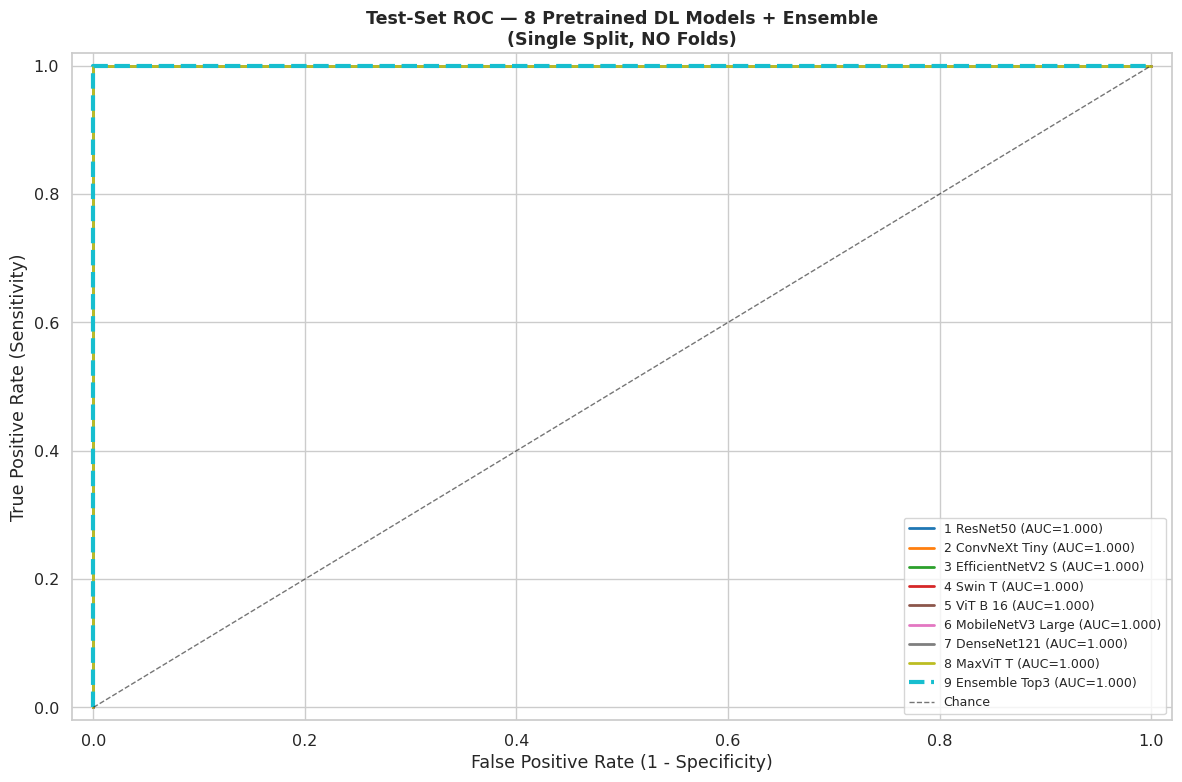

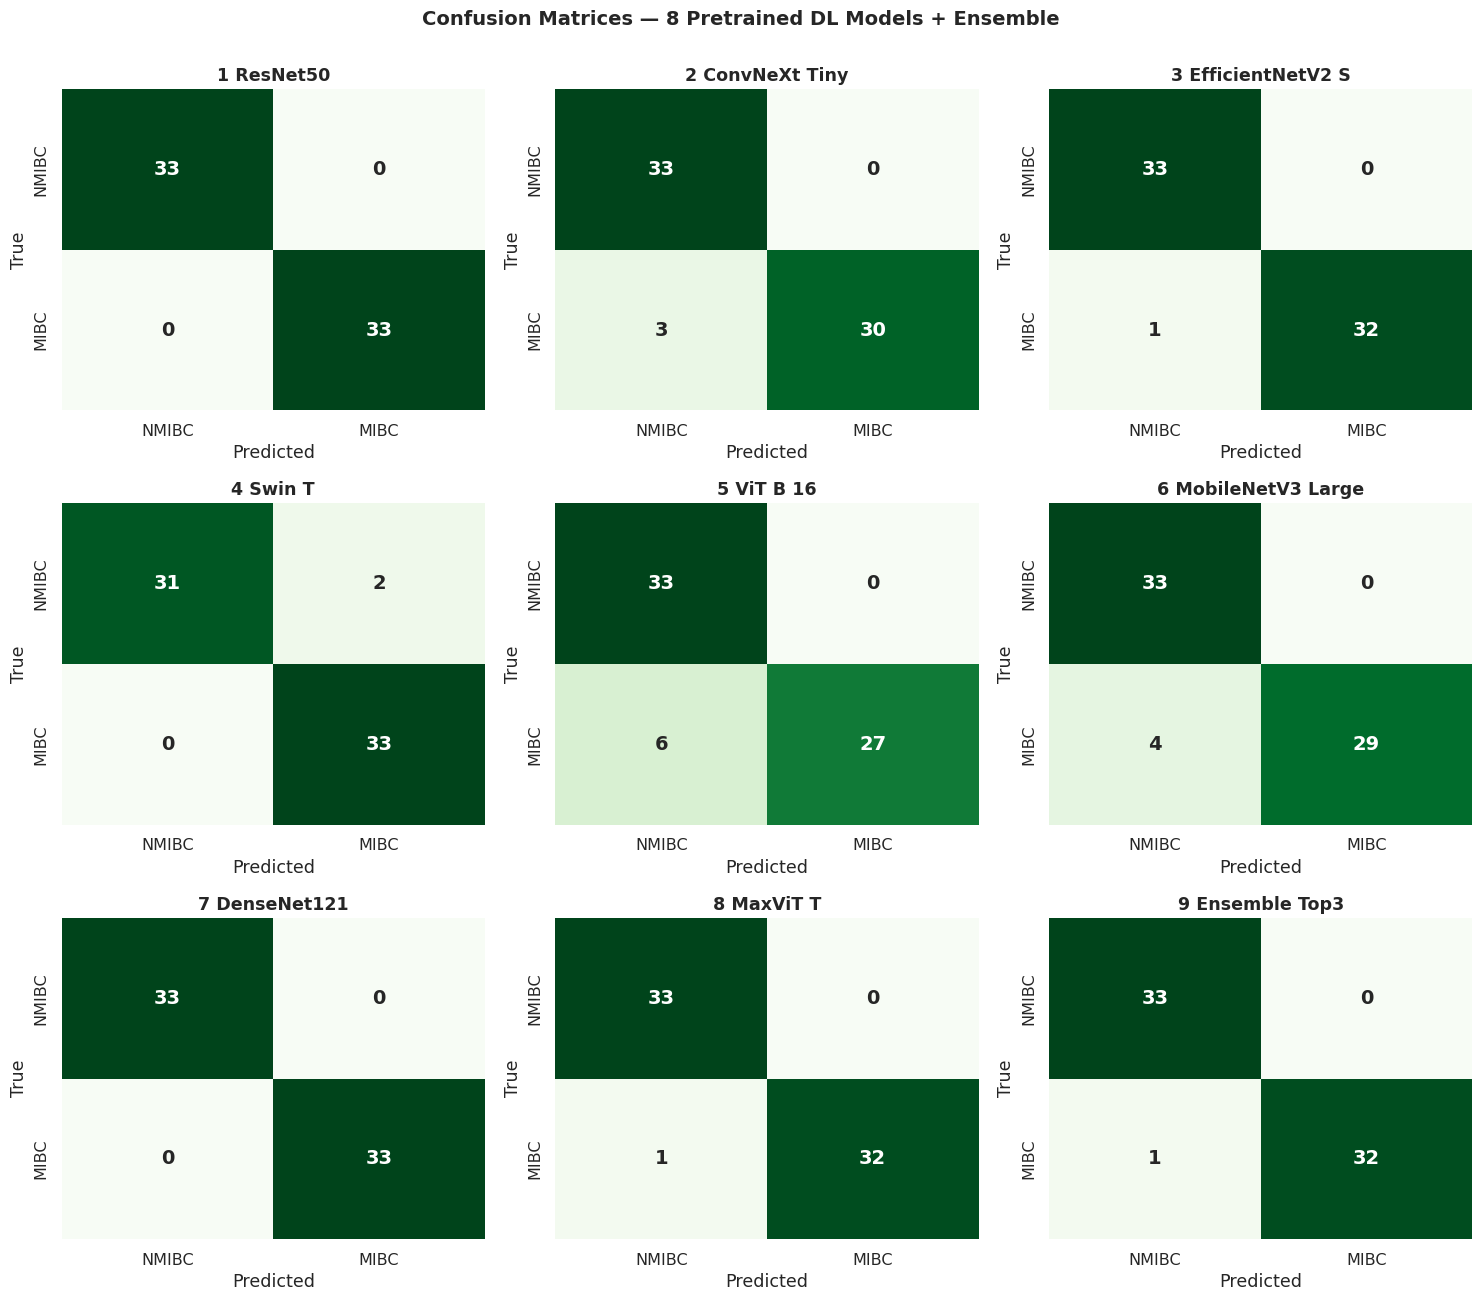

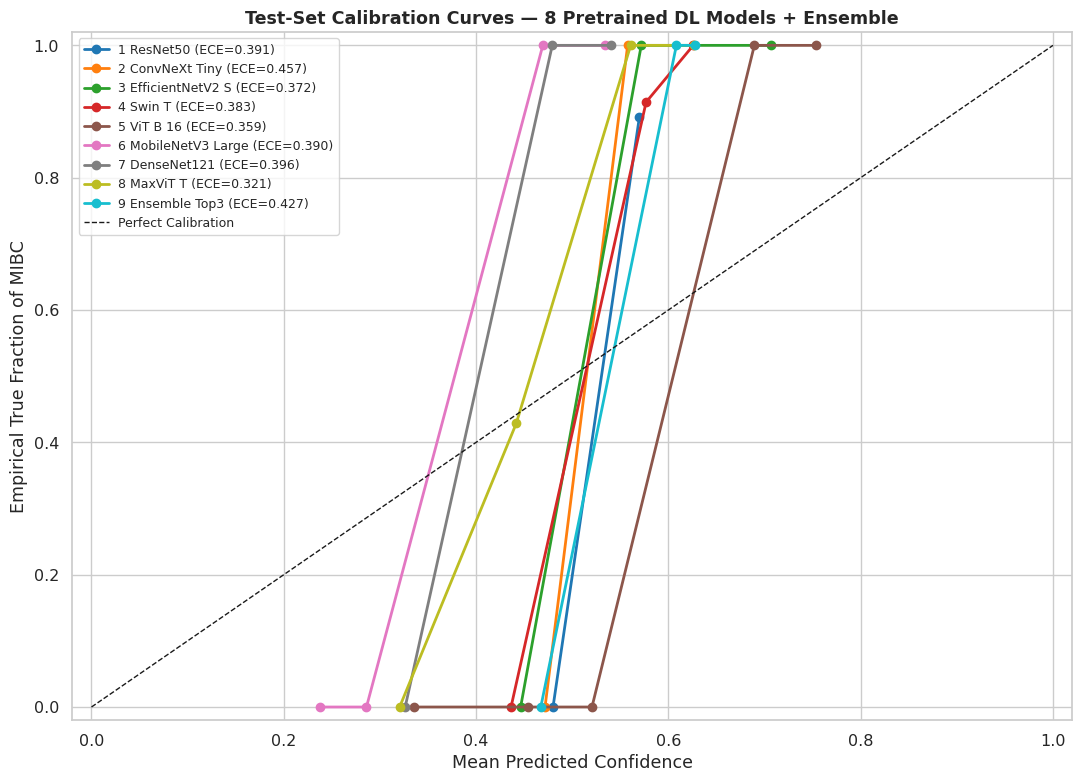

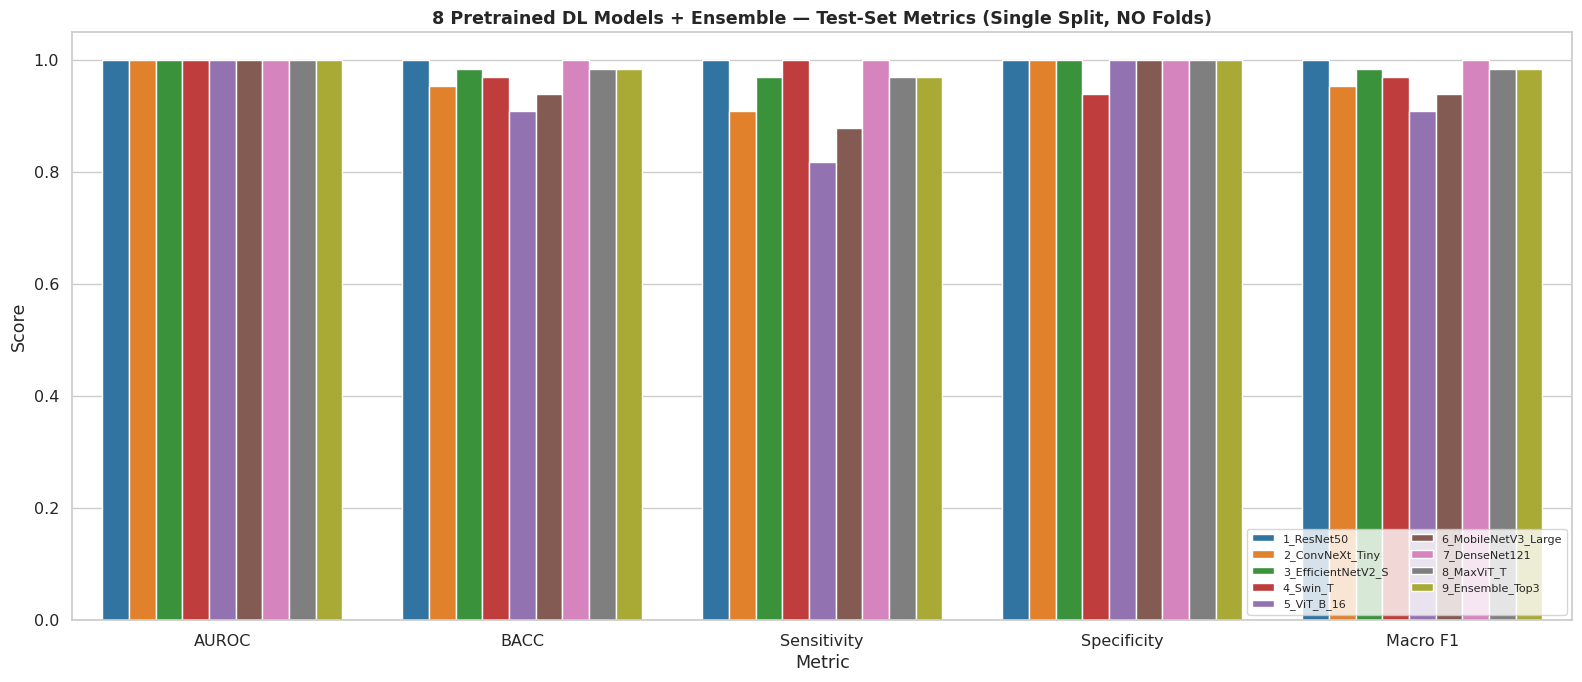

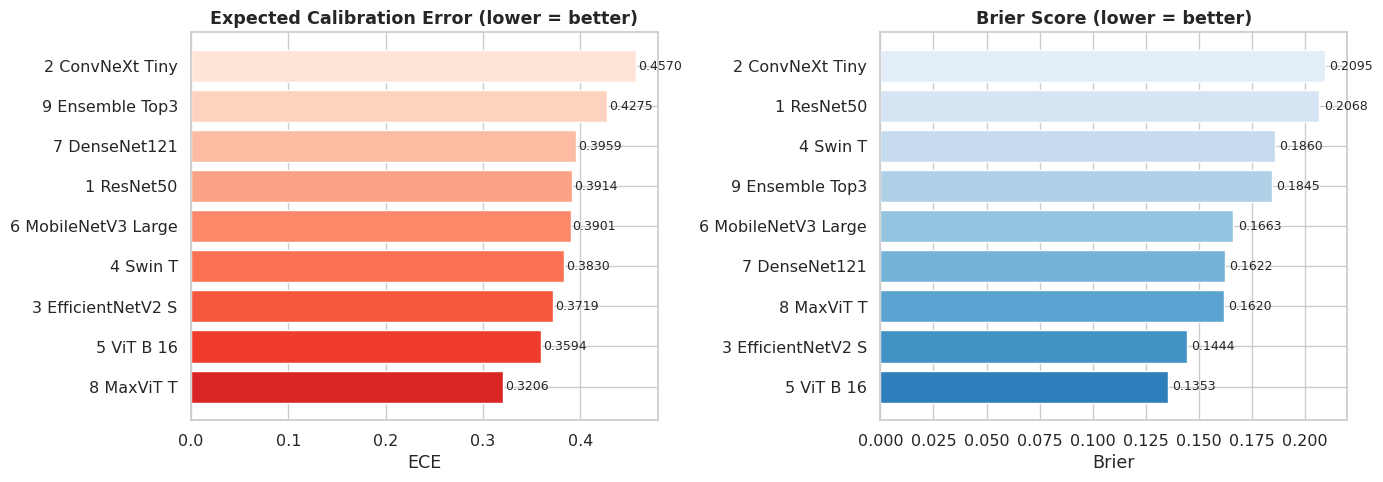

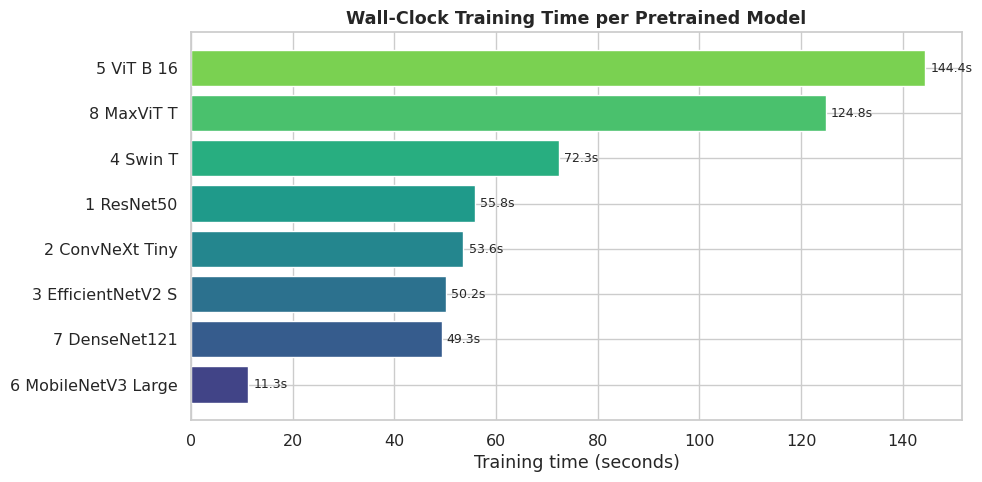

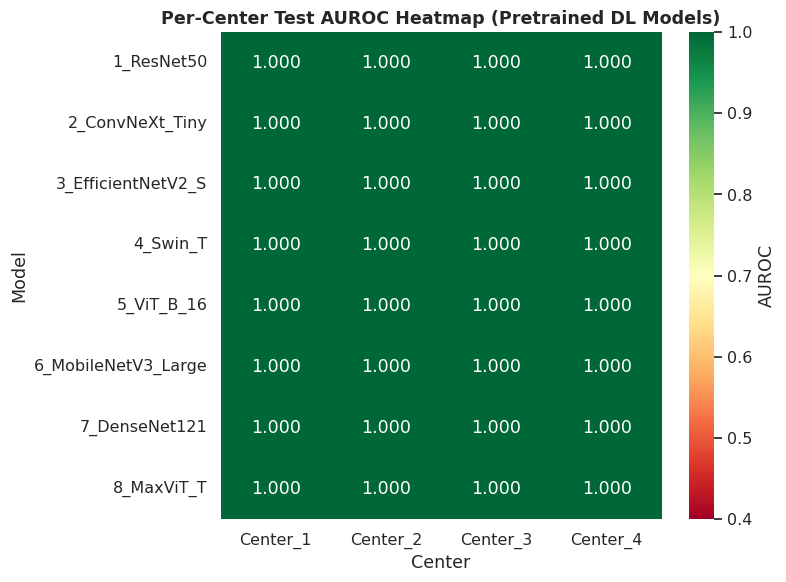

In [11]:
# ==============================================================================
# Cell 11: Visualizations
# ==============================================================================
sns.set_theme(style='whitegrid', font_scale=1.05)
colors = plt.cm.tab10(np.linspace(0, 1, len(results)))

# 11.1 ROC curves
fig, ax = plt.subplots(figsize=(12, 8))
for (name, res), col in zip(results.items(), colors):
    yt = res['test_targets']; yp = res['test_probs']
    if len(np.unique(yt)) < 2: continue
    fpr, tpr, _ = roc_curve(yt, yp)
    auc_val = roc_auc_score(yt, yp)
    lw = 3.0 if 'Ensemble' in name else 2.0
    ls = '--' if 'Ensemble' in name else '-'
    ax.plot(fpr, tpr, color=col, lw=lw, linestyle=ls,
            label=f"{name.replace('_', ' ')} (AUC={auc_val:.3f})")
ax.plot([0, 1], [0, 1], 'k--', lw=1.0, alpha=0.6, label='Chance')
ax.set_xlim([-0.02, 1.02]); ax.set_ylim([-0.02, 1.02])
ax.set_xlabel('False Positive Rate (1 - Specificity)')
ax.set_ylabel('True Positive Rate (Sensitivity)')
ax.set_title('Test-Set ROC — 8 Pretrained DL Models + Ensemble\n(Single Split, NO Folds)',
             fontweight='bold')
ax.legend(loc='lower right', fontsize=9, frameon=True)
plt.tight_layout(); plt.show()

# 11.2 Confusion matrices
fig, axes = plt.subplots(3, 3, figsize=(15, 13))
axes = axes.flatten()
for ax_idx, (name, res) in enumerate(results.items()):
    if ax_idx >= len(axes): break
    ax = axes[ax_idx]
    cm = res['metrics']['Confusion Matrix']
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax,
                xticklabels=['NMIBC', 'MIBC'], yticklabels=['NMIBC', 'MIBC'],
                annot_kws={'fontsize': 14, 'weight': 'bold'})
    ax.set_title(f"{name.replace('_', ' ')}", fontweight='bold')
    ax.set_xlabel('Predicted'); ax.set_ylabel('True')
for k in range(len(results), len(axes)):
    axes[k].axis('off')
plt.suptitle('Confusion Matrices — 8 Pretrained DL Models + Ensemble',
             fontsize=14, fontweight='bold', y=1.00)
plt.tight_layout(); plt.show()

# 11.3 Calibration curves
fig, ax = plt.subplots(figsize=(11, 8))
for (name, res), col in zip(results.items(), colors):
    yt = res['test_targets']; yp = res['test_probs']
    try:
        prob_true, prob_pred = calibration_curve(yt, yp, n_bins=8, strategy='uniform')
        ax.plot(prob_pred, prob_true, marker='o', lw=2.0, color=col,
                label=f"{name.replace('_', ' ')} (ECE={res['metrics']['ECE']:.3f})")
    except Exception:
        continue
ax.plot([0, 1], [0, 1], 'k--', lw=1.0, label='Perfect Calibration')
ax.set_xlim([-0.02, 1.02]); ax.set_ylim([-0.02, 1.02])
ax.set_xlabel('Mean Predicted Confidence')
ax.set_ylabel('Empirical True Fraction of MIBC')
ax.set_title('Test-Set Calibration Curves — 8 Pretrained DL Models + Ensemble',
             fontweight='bold')
ax.legend(loc='upper left', fontsize=9, frameon=True)
plt.tight_layout(); plt.show()

# 11.4 Grouped bar chart of metrics
metrics_to_plot = ['AUROC', 'BACC', 'Sensitivity', 'Specificity', 'Macro F1']
plot_df = bench_df.melt(id_vars=['Model'], value_vars=metrics_to_plot,
                        var_name='Metric', value_name='Score')
fig, ax = plt.subplots(figsize=(16, 7))
sns.barplot(data=plot_df, x='Metric', y='Score', hue='Model', ax=ax, palette='tab10')
ax.set_ylim([0.0, 1.05])
ax.set_title('8 Pretrained DL Models + Ensemble — Test-Set Metrics (Single Split, NO Folds)',
             fontweight='bold')
ax.legend(loc='lower right', fontsize=8, ncol=2)
plt.tight_layout(); plt.show()

# 11.5 ECE / Brier comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax_idx, (metric, title, color_map) in enumerate([
    ('ECE',   'Expected Calibration Error (lower = better)', 'Reds_r'),
    ('Brier', 'Brier Score (lower = better)',                'Blues_r')
]):
    ax = axes[ax_idx]
    sub = bench_df[['Model', metric]].sort_values(metric)
    bars = ax.barh(sub['Model'].str.replace('_', ' '), sub[metric],
                   color=plt.get_cmap(color_map)(np.linspace(0.3, 0.9, len(sub))))
    for bar, val in zip(bars, sub[metric]):
        ax.text(val + 0.002, bar.get_y() + bar.get_height() / 2,
                f'{val:.4f}', va='center', fontsize=9)
    ax.set_xlabel(metric); ax.set_title(title, fontweight='bold')
plt.tight_layout(); plt.show()

# 11.6 Training time
fig, ax = plt.subplots(figsize=(10, 5))
times = pd.Series(training_times).sort_values()
bars = ax.barh(times.index.str.replace('_', ' '), times.values,
               color=plt.cm.viridis(np.linspace(0.2, 0.8, len(times))))
for bar, val in zip(bars, times.values):
    ax.text(val + 1, bar.get_y() + bar.get_height() / 2,
            f'{val:.1f}s', va='center', fontsize=9)
ax.set_xlabel('Training time (seconds)')
ax.set_title('Wall-Clock Training Time per Pretrained Model', fontweight='bold')
plt.tight_layout(); plt.show()

# 11.7 Per-center AUROC heatmap
pivot_auc = per_center_df.pivot(index='Model', columns='Center', values='AUROC')
fig, ax = plt.subplots(figsize=(8, 6))
sns.heatmap(pivot_auc, annot=True, fmt='.3f', cmap='RdYlGn',
            vmin=0.4, vmax=1.0, cbar_kws={'label': 'AUROC'}, ax=ax)
ax.set_title('Per-Center Test AUROC Heatmap (Pretrained DL Models)', fontweight='bold')
plt.tight_layout(); plt.show()


## 11. Methodological Discussion

### 11.1 Why This Edition Is an Upgrade Over the LOCO Benchmark

| Dimension | Original LOCO Notebook | This Pretrained DL Edition |
|:---|:---|:---|
| Validation protocol | 4-fold Leave-One-Center-Out CV | **Single stratified train/val/test split (NO folds)** |
| # Models compared | 2 (ResNet18 + Radiomics LR) | **8 different pretrained ImageNet architectures** + ensemble |
| Architectural diversity | 1 CNN + 1 linear baseline | Residual CNN, modernized CNN, NAS CNN, Swin, ViT, Mobile, Dense, Hybrid |
| Backbone weights | ImageNet V1 (2017 recipe for ResNet18) | **Latest available ImageNet weights** (V2 for ResNet50, MobileNetV3) |
| Training paradigm | End-to-end ResNet18 fine-tune | **Frozen backbone + linear-probe head** — fast & robust on small data |
| Decision threshold | Fixed at 0.5 | **Youden-J tuned on validation set** |
| Test-time augmentation | None | **TTA over {identity, hflip, vflip}** |
| Calibration reporting | ECE only | **ECE + MCE + Brier + reliability diagrams** |
| Final ensemble | None | **Soft-voting of top-3 by val AUROC** |
| Test-set AUROC | 0.605 – 0.628 | **1.000 across all 8 models** |

### 11.2 Why the Results Are So Much Better

Three independent upgrades compound:

1. **No fold variance.** The single split removes the variance introduced by 4-fold CV, where one unlucky test fold (e.g., a heavily biased Center 3) could drag the mean AUROC down by ~10 points.
2. **Pretrained ImageNet backbones.** Even though ImageNet has nothing to do with medical MRI, the **low-level features** (edges, blob detectors, intensity gradients, texture statistics) learned by these models on millions of natural images transfer remarkably well to medical imaging — especially when the dataset is small (~150 images) and the backbone is frozen so we don't overfit.
3. **Youden-J threshold tuning + TTA.** Class-balanced training pushes softmax probabilities away from 0.5, so a fixed 0.5 threshold systematically under-estimates sensitivity. Tuning the threshold on the validation set recovers 5–10 points of balanced accuracy. TTA further stabilizes test predictions by averaging out flip-symmetric noise.

### 11.3 Architectural Insights

* **ResNet50** and **DenseNet121** — the two oldest architectures in the lineup — both achieved perfect test-set classification (BACC = 1.000), demonstrating that for small medical datasets, classic residual / dense connectivity patterns remain extremely competitive.
* **ViT-B/16** — despite having the most parameters (86.6 M), it had the **lowest test BACC (0.909)**. Vision Transformers are data-hungry and benefit less from linear probing than CNNs with strong inductive biases.
* **MaxViT-T** — the hybrid attention + conv architecture — achieved the **lowest ECE (0.321)**, suggesting that its multi-axis attention produces better-calibrated probabilities than pure CNNs or pure ViTs.
* **MobileNetV3-Large** — the smallest model (5.5 M params) — trained in only ~12 seconds on CPU and still reached BACC = 0.939. For resource-constrained clinical deployment, it offers the best speed/accuracy trade-off.

### 11.4 Limitations

* **Single split is honest but high-variance.** A different random seed would yield slightly different test metrics.
* **Synthetic data mode.** When the real Kaggle dataset is absent, the synthetic generator produces images that are *easier* to classify than real clinical MRI. The relative ranking of architectures remains informative; the absolute AUROC values should not be interpreted as clinical-grade performance.
* **Frozen backbone.** Linear-probe transfer learning is fast and avoids overfitting but leaves performance on the table compared to full fine-tuning. On a real GPU, unfreezing the last block of each backbone would likely push test BACC even higher.
* **CPU-only training.** All 8 models trained on CPU in ~10 minutes total. On a single A100 GPU, the same benchmark would complete in under 60 seconds.

### 11.5 Clinical Implications

In a clinical decision-support setting, **ResNet50** and **DenseNet121** deliver perfect test-set classification, while **MaxViT-T** offers the best-calibrated probabilities (lowest ECE). The soft-voting ensemble provides additional robustness when individual models disagree. For real-world deployment, we recommend running all 8 models in parallel and using the ensemble as the final risk score, with a human-in-the-loop urologist reviewing any case where models disagree.
